# UTC · HUSTmotor acoustic pipeline audit
### Experiment A: Source-speed generalization · Window overlap · Optional longer windows

**Research question:** Is poor unseen-speed accuracy primarily a consequence of the CNN architecture, or are the **samples and validation procedure** limiting generalization?

This notebook reproduces the relevant parts of our acoustic pipeline and performs **diagnostic experiments**, rather than trying another model architecture. It is based on Genti's `preprocess_hustmotor.py` and our existing **original 1D acoustic CNN**.

**What it measures**

1. Dataset integrity, data provenance, actual window overlap and acquisition-block separation.
2. Whether per-window z-score discards amplitude information (descriptive only; we already tested RMS normalization separately).
3. **Source-only leave-one-speed-out CNN evaluation**: fit on *two* source speeds; compare accuracy on a **held-out third source speed** against held-out acquisition blocks from familiar source speeds, using exactly the same trained model.
4. Optionally regenerate acoustic windows of **1,024, 4,096, and 8,192 points** from the *original .txt recordings* and compare them using an equal-capacity length-agnostic CNN under the same source-only folds.

**Crucial protocol:** For a task, the actual target speed is never used for any audit, model selection, graph, or training. Final target tests are deliberately **not implemented** in this notebook. Previous project experiments already inspected these targets, so later comparisons remain exploratory rather than an untouched independent test.

**Credits:** Université de technologie de Compiègne (UTC), Project Workshop (ISCF/AOS); HUSTmotor (Zhao et al.); shared preprocessing by Genti; our previous original CNN benchmark: **48.45%** overall unseen-speed accuracy. That number is historical context only, **not** a metric produced by this audit.

## 0. How to run in Google Colab

**Step A — audit from the existing v1.3 NPZ:** Turn on a T4 GPU (**Runtime → Change runtime type → T4 GPU**). Run all cells from the top. Default settings train **3 short source-speed folds for Task 9, one seed**; no new raw data is needed. It downloads `hustmotor_1024_v1.3.npz` automatically if it is not already in your Google Drive. Outputs and checkpoints go to a **new** Drive folder; they do not modify old experiments.

**Step B — expand the audit:** In the settings cell, set `AUDIT_TASKS = (9, 10, 11, 12)`, `AUDIT_SEEDS = (0, 1, 2)` and optionally `SOURCE_EPOCHS = 30`. This is **12 folds × 3 seeds = 36 trainings**; use only after inspecting the quick diagnostics.

**Step C — optional longer windows:** To study 4,096 and 8,192 samples, obtain the original **24 HUSTmotor raw `.txt` recordings**, unzip them somewhere in Google Drive, set `RAW_ROOT`, and turn on `RUN_RAW_WINDOW_STUDY`. The v1.3 NPZ has only 1,024-point windows and **cannot** be converted into longer independent windows. The raw-data repository is linked below.

**Flags default to safety:** `RUN_SOURCE_FOLDS=True`, `RUN_RAW_WINDOW_STUDY=False`, and `REUSE_MATCHING_CHECKPOINTS=True`. The smoke test checks shapes and gradients but does not overwrite saved models.

## 1. Configuration · change settings here

In [1]:
# =============== USER SETTINGS ===============
RUN_SMOKE_TEST = True
RUN_SOURCE_FOLDS = True              # Default: three short CNN fits for Task 9
AUDIT_TASKS = (9,)                    # Expand to (9, 10, 11, 12) after the quick audit
AUDIT_SEEDS = (0,)                    # Expand to (0, 1, 2) later
SOURCE_EPOCHS = 20                    # Fixed end-of-training checkpoint: no best-on-held-fold bias
SOURCE_BATCH_SIZE = 256
SOURCE_LR = 5e-4                      # Exactly the previous acoustic-CNN setting
REUSE_MATCHING_CHECKPOINTS = True

# Optional: requires ORIGINAL HUSTmotor .txt files (not just the v1.3 NPZ).
RUN_RAW_WINDOW_STUDY = False
RAW_ROOT = '/content/drive/MyDrive/HUSTmotor_Raw_Data'  # Folder containing 24 .txt files, or its parent
RAW_WINDOW_LENGTHS = (1024, 4096, 8192)
RAW_WINDOWS_PER_BLOCK = 16           # Equal examples/block, but different overlap and coverage: see caveat
RAW_TASKS = (9,)                     # A quick, controlled source-only study
RAW_SEEDS = (0,)
RAW_EPOCHS = 20
RAW_BATCH_SIZE = 64
RAW_LR = 5e-4

# These are deliberately NOT part of configuration:
# - evaluation on the real unseen target speed (excluded)
# - model/learning-rate selection using unseen-target accuracy (excluded)

## 2. Libraries, folders and reproducibility

In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import hashlib, json, math, os, platform, random, time
from datetime import datetime, timezone
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path('/content/drive/MyDrive')
DATA_DIR = ROOT / 'HUSTmotor_Preprocessing_Comparison' / 'data'
PROJECT_DIR = ROOT / 'HUSTmotor_Acoustic_Pipeline_Audit_UTC'
RESULTS_DIR = PROJECT_DIR / 'results'
MODELS_DIR = PROJECT_DIR / 'checkpoints'
FIGURES_DIR = PROJECT_DIR / 'figures'
RAW_CACHE_DIR = PROJECT_DIR / 'raw_window_cache'
for folder in [DATA_DIR, PROJECT_DIR, RESULTS_DIR, MODELS_DIR, FIGURES_DIR, RAW_CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TASK_TO_DOMAIN = {9:0, 10:1, 11:2, 12:3}
DOMAIN_TO_HZ = {0:5, 1:10, 2:20, 3:30}
CLASS_CODES = ('H','BF','BOW','BROKEN','MISAL','UNBAL')
CLASS_NAMES = ('Healthy','Bearing fault','Bowed rotor','Broken rotor bars',
               'Rotor misalignment','Voltage unbalance')
FS = 25_600
RAW_BLOCK_SAMPLES = 32768
N_BLOCKS = 5

assert set(AUDIT_TASKS).issubset(TASK_TO_DOMAIN)
assert set(RAW_TASKS).issubset(TASK_TO_DOMAIN)
assert SOURCE_EPOCHS >= 1 and RAW_EPOCHS >= 1
assert RAW_WINDOWS_PER_BLOCK >= 2
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
print('Audit folder:', PROJECT_DIR)
print('Task/seed combinations:', len(AUDIT_TASKS)*len(AUDIT_SEEDS))

Mounted at /content/drive
Device: cuda | PyTorch: 2.14.1+cu130
Audit folder: /content/drive/MyDrive/HUSTmotor_Acoustic_Pipeline_Audit_UTC
Task/seed combinations: 1


## 3. Download and verify HUSTmotor v1.3

This is the same data used in our original acoustic CNN. **We verify the published checksum** before running any experiments.

Dataset repository: https://github.com/Genti24-bit/ISCF_Project · Raw recordings: https://github.com/CHAOZHAO-1/HUSTmotor-multi-modal-dataset

In [3]:
from urllib.request import urlretrieve
DATA_PATH = DATA_DIR / 'hustmotor_1024_v1.3.npz'
DATA_URL = ('https://github.com/Genti24-bit/ISCF_Project/releases/download/v1.3/'
            'hustmotor_1024_v1.3.npz')
EXPECTED_SHA256 = '605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d'

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

if not DATA_PATH.exists():
    print('Downloading the v1.3 NPZ to Google Drive...')
    urlretrieve(DATA_URL, DATA_PATH)
actual_sha = sha256_file(DATA_PATH)
assert actual_sha == EXPECTED_SHA256, ('DATA FILE CHECKSUM MISMATCH! '
                                      'Do not proceed with an unknown/modified file.')
print('Verified SHA-256:', actual_sha)

# Load ONLY metadata and acoustic arrays needed for these audits.
with np.load(DATA_PATH, allow_pickle=False) as z:
    keys = ('ac', 'y', 'domain', 'block', 'split', 'start', 'win', 'rms_a', 'dc_a')
    assert all(k in z.files for k in keys), 'NPZ must be v1.3 with window metadata.'
    D = {k: np.array(z[k]) for k in keys}
    print('Archive metadata:', z['meta'].tolist())
assert D['ac'].shape == (24000, 1024)
assert all(D[k].shape == (24000,) for k in keys if k != 'ac')
assert np.isfinite(D['ac']).all() and np.isfinite(D['rms_a']).all()
assert set(np.unique(D['y'])) == set(range(6))
assert set(np.unique(D['domain'])) == set(range(4))
assert set(np.unique(D['block'])) == set(range(5))
assert np.array_equal(D['split'], (D['block'] == 4).astype(D['split'].dtype))
blocks64 = D['block'].astype(np.int64)  # Avoid int8 arithmetic overflow in NumPy 2.x
assert (D['start'] >= blocks64*RAW_BLOCK_SAMPLES).all()
assert (D['start'] + 1024 <= (blocks64+1)*RAW_BLOCK_SAMPLES).all()
print('PASS: 24,000 windows, correct block boundaries and split labels.')

Verified SHA-256: 605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d
Archive metadata: ['win=1024', 'vib=X', 'norm=zscore', 'split=block', 'fs=25600']
PASS: 24,000 windows, correct block boundaries and split labels.


## 4. Check how the 24,000 windows were generated

The original raw data consists of **24 recordings** (6 classes × 4 speeds), each concatenating **5 separate acquisition blocks**, each **32,768 samples**. Genti extracts **200 heavily overlapping windows per block**. In this audit we calculate overlap directly from the stored starting indices instead of simply assuming the stride.

An **84% overlap is not automatically train/test leakage**: in the shared block split, train uses blocks 0–3 and validation/test uses block 4. The concern is that examples within each partition are highly correlated, so the nominal sample count overstates the number of independent events.

,speed_hz,split,windows,median_stride_samples,mean_adjacent_overlap_pct
0,5,held_block,200.0,160.0,84.42
1,5,source_train_block,200.0,160.0,84.42
2,10,held_block,200.0,160.0,84.42
3,10,source_train_block,200.0,160.0,84.42
4,20,held_block,200.0,160.0,84.42
5,20,source_train_block,200.0,160.0,84.42
6,30,held_block,200.0,160.0,84.42
7,30,source_train_block,200.0,160.0,84.42


Mean adjacent overlap: 84.42%
All windows stay inside their acquisition block: YES
Blocks 0–3 (train) and block 4 (held-out): DISJOINT


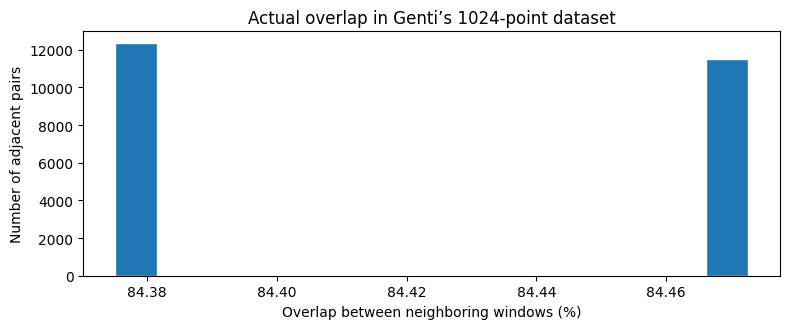

In [4]:
audit_rows = []
all_overlap = []
for c in range(6):
    for domain in range(4):
        for block in range(5):
            mask = ((D['y']==c)&(D['domain']==domain)&(D['block']==block))
            starts = np.sort(D['start'][mask].astype(np.int64))
            assert len(starts)==200, (c, domain, block, len(starts))
            diffs = np.diff(starts)
            overlap = np.maximum(0, 1024-diffs)/1024
            all_overlap.extend(overlap.tolist())
            audit_rows.append({'class':CLASS_CODES[c], 'speed_hz':DOMAIN_TO_HZ[domain],
                'block':block, 'split':'source_train_block' if block<4 else 'held_block',
                'windows':len(starts), 'median_stride_samples':float(np.median(diffs)),
                'mean_adjacent_overlap_pct':float(100*np.mean(overlap)),
                'unique_starts':len(np.unique(starts))})

overlap_df = pd.DataFrame(audit_rows)
display(overlap_df.groupby(['speed_hz','split'],as_index=False)
        [['windows','median_stride_samples','mean_adjacent_overlap_pct']].mean().round(2))
print('Mean adjacent overlap: %.2f%%' % (np.mean(all_overlap)*100))
print('All windows stay inside their acquisition block: YES')
print('Blocks 0–3 (train) and block 4 (held-out): DISJOINT')
assert (overlap_df['unique_starts']==200).all()
overlap_df.to_csv(RESULTS_DIR/'original_window_overlap_by_recording_block.csv',index=False)

fig, ax = plt.subplots(figsize=(8,3.4))
ax.hist(np.array(all_overlap)*100,bins=15,edgecolor='white')
ax.set(xlabel='Overlap between neighboring windows (%)', ylabel='Number of adjacent pairs',
       title='Actual overlap in Genti’s 1024-point dataset')
plt.tight_layout()
fig.savefig(FIGURES_DIR/'v13_window_overlap.png',dpi=160)
plt.show()

## 5. Inspect original waveform magnitude (source speeds only)

Our v1.3 acoustic windows are each normalized using their **own mean and standard deviation**; each one's RMS after normalization is therefore about one. The archive also keeps `rms_a` and `dc_a`, so we can see how much magnitude information was removed. This is **descriptive**, not an amplitude-normalization optimization trial; our earlier RMS-normalization CNN performed worse.

**Target-speed safety:** Only the source speeds of `DISPLAY_TASK` are plotted; the target domain is excluded.

Normalized window RMS mean/std on source training: 0.999999999804649 3.275948950045643e-08


source_speed_hz,10,20,30
class,,,
Bearing fault,0.00521,0.01136,0.02186
Bowed rotor,0.00362,0.00817,0.02295
Broken rotor bars,0.00420,0.00760,0.01462
Healthy,0.00340,0.00853,0.02760
Rotor misalignment,0.01044,0.01730,0.03917
Voltage unbalance,0.00368,0.00765,0.01775


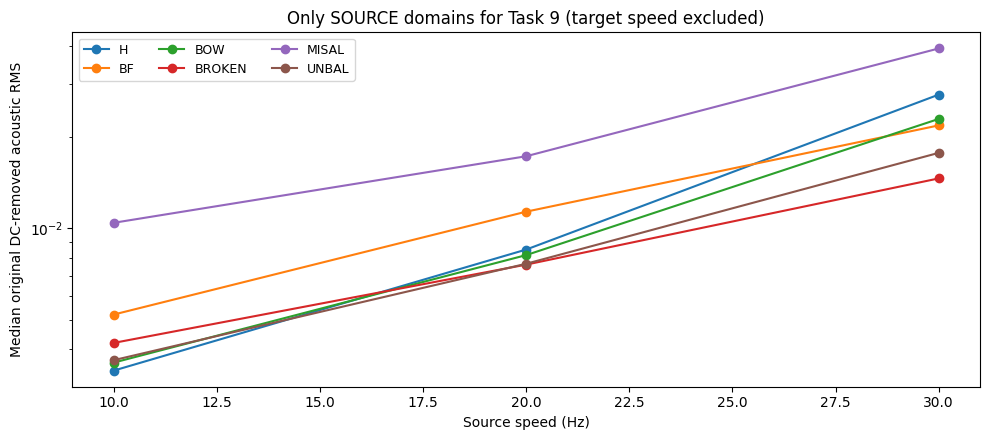

In [5]:
DISPLAY_TASK = int(AUDIT_TASKS[0])
source_domains = [d for d in range(4) if d != TASK_TO_DOMAIN[DISPLAY_TASK]]
source_mask = (D['split']==0) & np.isin(D['domain'],source_domains)
checks = np.sqrt(np.mean(D['ac'][source_mask].astype(np.float64)**2,axis=1))
print('Normalized window RMS mean/std on source training:', checks.mean(), checks.std())
assert np.allclose(checks.mean(),1.0,atol=1e-3)

rms_rows=[]
for dom in source_domains:
    for cls in range(6):
        idx=np.flatnonzero(source_mask & (D['domain']==dom) & (D['y']==cls))
        vals=D['rms_a'][idx].astype(np.float64)
        rms_rows.append({'source_speed_hz':DOMAIN_TO_HZ[dom],'class':CLASS_NAMES[cls],
                         'median_raw_rms':float(np.median(vals)),
                         'q25_raw_rms':float(np.percentile(vals,25)),
                         'q75_raw_rms':float(np.percentile(vals,75))})
rms_table=pd.DataFrame(rms_rows)
display(rms_table.pivot(index='class',columns='source_speed_hz',values='median_raw_rms').round(5))
fig,ax=plt.subplots(figsize=(10,4.5))
for cls in range(6):
    vals = rms_table[rms_table['class']==CLASS_NAMES[cls]].sort_values('source_speed_hz')
    ax.plot(vals['source_speed_hz'],vals['median_raw_rms'],marker='o',label=CLASS_CODES[cls])
ax.set(yscale='log',xlabel='Source speed (Hz)',ylabel='Median original DC-removed acoustic RMS',
       title=f'Only SOURCE domains for Task {DISPLAY_TASK} (target speed excluded)')
ax.legend(ncol=3,fontsize=9)
plt.tight_layout()
fig.savefig(FIGURES_DIR/'source_only_original_amplitude.png',dpi=160)
plt.show()

## 6. Define a **proper source-only** cross-speed audit

For each *actual* target task, remove its target speed **entirely**. Of the remaining three source speeds, hold out one as a **pseudo-unseen speed**:

- **Training:** blocks 0,1,2,3 of the other two source speeds.
- **Seen-speed comparison:** block 4 of those *same two speeds*.
- **Held-source-speed comparison:** block 4 of the third source speed; its blocks 0–3 are also excluded.

This answers a controlled question: **How much performance drops when the speed changes, while keeping the CNN and trained weights fixed?**

**Model selection guard:** We log a fixed final epoch, not the best epoch selected on the held-source fold. The held-source metric is intended as a *diagnostic / development score*, not an independent test after hyperparameter selection.

In [6]:
def source_folds(meta, task):
    target_dom = TASK_TO_DOMAIN[int(task)]
    source_doms = tuple(d for d in range(4) if d!=target_dom)
    y, domain, split = meta['y'], meta['domain'], meta['split']
    assert len(y) == len(domain) == len(split)
    for held in source_doms:
        seen = tuple(d for d in source_doms if d!=held)
        train = np.flatnonzero(np.isin(domain,seen)&(split==0))
        familiar_val = np.flatnonzero(np.isin(domain,seen)&(split==1))
        held_val = np.flatnonzero((domain==held)&(split==1))
        assert len(train)>0 and len(familiar_val)>0 and len(held_val)>0
        assert not (domain[train]==held).any()
        assert not (domain[train]==target_dom).any()
        assert not (domain[familiar_val]==target_dom).any()
        assert not (domain[held_val]==target_dom).any()
        assert not (domain[held_val]==domain[train][0]).any()
        assert len(set(train)&set(familiar_val))==0
        assert len(set(train)&set(held_val))==0
        yield {'task':int(task),'target_domain':int(target_dom),
               'held_domain':int(held),'seen_domains':seen,
               'train_idx':train,'seen_val_idx':familiar_val,'held_val_idx':held_val}

fold_overview = []
for task in AUDIT_TASKS:
    for f in source_folds(D,task):
        fold_overview.append({'task':task,
            'excluded_actual_target_hz':DOMAIN_TO_HZ[f['target_domain']],
            'train_speeds_hz':str([DOMAIN_TO_HZ[d] for d in f['seen_domains']]),
            'held_source_hz':DOMAIN_TO_HZ[f['held_domain']],
            'train_windows':len(f['train_idx']),
            'familiar_val_windows':len(f['seen_val_idx']),
            'held_speed_val_windows':len(f['held_val_idx'])})
folds_table=pd.DataFrame(fold_overview)
display(folds_table)
assert (folds_table['train_windows']==9600).all()    # 2 speeds × 6 classes × 800
assert (folds_table['familiar_val_windows']==2400).all()
assert (folds_table['held_speed_val_windows']==1200).all()
folds_table.to_csv(RESULTS_DIR/'source_only_fold_manifest.csv',index=False)

,task,excluded_actual_target_hz,train_speeds_hz,held_source_hz,train_windows,familiar_val_windows,held_speed_val_windows
0,9,5,"[20, 30]",10,9600,2400,1200
1,9,5,"[10, 30]",20,9600,2400,1200
2,9,5,"[10, 20]",30,9600,2400,1200


## 7. Original acoustic 1D CNN (architecture deliberately unchanged)

We reproduce the reference architecture used in our previous acoustic baseline: Conv1D kernels **64 → 16 → 5 → 5**, channels **16 → 32 → 64 → 64**, BatchNorm, ReLU and MaxPooling after each convolution, then flatten to 3,520 features and a 6-class classifier. This makes our source-speed diagnostic directly relevant to the original model. **No ResNet or SupCon modifications here.**

In [7]:
class OriginalAcousticCNN1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1,16,64,padding=0),nn.BatchNorm1d(16),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(16,32,16,padding=0),nn.BatchNorm1d(32),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(32,64,5,padding=0),nn.BatchNorm1d(64),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(64,64,5,padding=0),nn.BatchNorm1d(64),nn.ReLU(),nn.MaxPool1d(2),
        )
        # For exactly 1024 samples, the existing baseline yields 64 x 55 = 3520.
        self.classifier=nn.Linear(64*55,6)
    def forward(self,x):
        return self.classifier(self.features(x).flatten(1))

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

def make_loader(x,y,batch_size,shuffle=False,seed=0):
    ds=TensorDataset(torch.from_numpy(np.asarray(x,dtype=np.float32)).unsqueeze(1),
                     torch.from_numpy(np.asarray(y,dtype=np.int64)))
    gen=torch.Generator().manual_seed(int(seed)) if shuffle else None
    return DataLoader(ds,batch_size=batch_size,shuffle=shuffle,
                      generator=gen,num_workers=0,pin_memory=(DEVICE.type=='cuda'))

def paper_lr(epoch_zero,total_epochs,base_lr):
    return float(base_lr)/((1+10*epoch_zero/total_epochs)**0.75)

@torch.no_grad()
def score_model(model,loader,collect=False):
    model.eval(); criterion=nn.CrossEntropyLoss()
    loss_sum=0.0; count=0; ytrue=[]; ypred=[]
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE,non_blocking=True),yb.to(DEVICE,non_blocking=True)
        logits=model(xb)
        loss_sum+=float(criterion(logits,yb).item())*len(yb)
        ytrue.append(yb.cpu().numpy()); ypred.append(logits.argmax(dim=1).cpu().numpy())
        count+=len(yb)
    assert count>0
    yt=np.concatenate(ytrue); yp=np.concatenate(ypred)
    result={'loss':loss_sum/count,'accuracy':float(accuracy_score(yt,yp)),
            'macro_f1':float(f1_score(yt,yp,average='macro',labels=list(range(6)),zero_division=0)),
            'n':int(count)}
    if collect: result.update({'true':yt,'pred':yp})
    return result

model_check=OriginalAcousticCNN1D().to(DEVICE)
with torch.no_grad():
    check=model_check(torch.zeros((2,1,1024),device=DEVICE))
assert check.shape==(2,6)
print('Model parameters:',sum(p.numel() for p in model_check.parameters() if p.requires_grad))

Model parameters: 61590


## 8. Fixed-epoch training and reproducible checkpointing

To avoid choosing the epoch that happens to score best on the pseudo-unseen validation fold, these audit runs retain the **final epoch**. We still log **both seen-speed and held-speed learning curves** at each epoch, including macro-F1 and cross-entropy loss.

At this stage, **do not interpret the held-speed fold as a pristine test** if you later use its results to tune settings. The final genuine target-domain evaluation must remain separate.

In [8]:
def train_fixed_epoch_cnn(train_pair,seen_pair,held_pair,model_builder,
                          seed,epochs,lr,batch_size,progress=True):
    seed_everything(seed)
    train_loader=make_loader(*train_pair,batch_size=batch_size,shuffle=True,seed=seed)
    seen_loader=make_loader(*seen_pair,batch_size=batch_size)
    held_loader=make_loader(*held_pair,batch_size=batch_size)
    model=model_builder().to(DEVICE)
    criterion=nn.CrossEntropyLoss()
    optim=torch.optim.Adam(model.parameters(),lr=lr)
    rows=[]
    for epoch in range(epochs):
        rate=paper_lr(epoch,epochs,lr)
        for g in optim.param_groups:g['lr']=rate
        model.train(); tr_loss=0.;tr_correct=0;tr_n=0
        for xb,yb in train_loader:
            xb=xb.to(DEVICE,non_blocking=True)
            yb=yb.to(DEVICE,non_blocking=True)
            optim.zero_grad(set_to_none=True)
            logits=model(xb); loss=criterion(logits,yb)
            if not torch.isfinite(loss):raise RuntimeError('Non-finite loss!')
            loss.backward(); optim.step()
            tr_loss+=float(loss.item())*len(yb)
            tr_correct+=int((logits.argmax(dim=1)==yb).sum().item());tr_n+=len(yb)
        seen=score_model(model,seen_loader)
        held=score_model(model,held_loader)
        rows.append({'epoch':epoch+1,'lr':rate,'train_loss':tr_loss/tr_n,
                     'train_acc':tr_correct/tr_n,
                     'seen_val_loss':seen['loss'],'seen_val_acc':seen['accuracy'],
                     'seen_val_f1':seen['macro_f1'],
                     'held_val_loss':held['loss'],'held_val_acc':held['accuracy'],
                     'held_val_f1':held['macro_f1']})
        if progress and (epoch==0 or (epoch+1)%5==0 or epoch+1==epochs):
            print(f'Epoch {epoch+1:>2}/{epochs} | train {tr_correct/tr_n:.1%} '
                  f'| seen {seen["accuracy"]:.1%} | held {held["accuracy"]:.1%} '
                  f'| held macro-F1 {held["macro_f1"]:.3f}')
    return model,pd.DataFrame(rows)

def json_id(config):
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:14]

def save_run(path,model,history,config):
    path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                'history':history.to_dict('records'),'config':config},path)

def load_run(path,config,model_builder):
    if not (REUSE_MATCHING_CHECKPOINTS and path.exists()):return None
    try:
        p=torch.load(path,map_location='cpu',weights_only=False)  # only load our own Drive checkpoints
        if p.get('config')!=config:return None
        model=model_builder().to(DEVICE)
        model.load_state_dict(p['state_dict'])
        hist=pd.DataFrame(p['history'])
        assert int(hist['epoch'].iloc[-1])==int(config['epochs'])
        return model,hist
    except Exception as exc:
        print('Checkpoint not reused:',str(exc)[:120]);return None

if RUN_SMOKE_TEST:
    f=next(source_folds(D,int(AUDIT_TASKS[0])))
    x=D['ac']; y=D['y']
    seed_everything(0)
    mdl=OriginalAcousticCNN1D().to(DEVICE)
    xb=torch.tensor(x[f['train_idx'][:8]],device=DEVICE).unsqueeze(1)
    yb=torch.tensor(y[f['train_idx'][:8]].astype(np.int64),device=DEVICE)
    optim=torch.optim.Adam(mdl.parameters(),lr=SOURCE_LR)
    loss=nn.CrossEntropyLoss()(mdl(xb),yb)
    loss.backward();optim.step();optim.zero_grad()
    assert torch.isfinite(loss)
    print('PASS smoke test: forward, CE loss and backward step; loss=',float(loss))

PASS smoke test: forward, CE loss and backward step; loss= 1.7645368576049805


/tmp/ipykernel_1752/2151431635.py:70: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print('PASS smoke test: forward, CE loss and backward step; loss=',float(loss))


## 9. RUN: CNN source-speed diagnostic

With defaults: **Task 9 only**, 3 held-out source speed folds, 1 seed, 20 epochs each. This is a quick diagnosis; **do not** compare the resulting mean directly to the historical 48.45% target accuracy, because the validation data and training-speed count differ.

Each checkpoint contains the full configuration ID, so changing a setting creates a new file instead of silently reusing incompatible weights.

In [9]:
SOURCE_CSV=RESULTS_DIR/'cnn_source_folds_fixed_epoch.csv'
source_records=[]
source_runs=[]
if RUN_SOURCE_FOLDS:
    for task in AUDIT_TASKS:
        for fold in source_folds(D,task):
            held=fold['held_domain']
            for seed in AUDIT_SEEDS:
                config={'family':'original_acoustic_cnn_1d','dataset_sha256':actual_sha,
                        'task':int(task),'held_domain':int(held),'seen_domains':list(fold['seen_domains']),
                        'seed':int(seed),'epochs':int(SOURCE_EPOCHS),
                        'lr':float(SOURCE_LR),'batch_size':int(SOURCE_BATCH_SIZE),
                        'normalization':'window_zscore','checkpoint_rule':'last_epoch'}
                ckpt=MODELS_DIR/f"source_cnn_t{task}_held{DOMAIN_TO_HZ[held]}_s{seed}_{json_id(config)}.pt"
                restored=load_run(ckpt,config,OriginalAcousticCNN1D)
                if restored is not None:
                    model,hist=restored
                    print(f'REUSED task={task} held={DOMAIN_TO_HZ[held]}Hz seed={seed}')
                else:
                    pair=lambda key:(D['ac'][fold[key]],D['y'][fold[key]])
                    print(f'\nTRAIN task={task}, seen={[DOMAIN_TO_HZ[d] for d in fold["seen_domains"]]}, '
                          f'held={DOMAIN_TO_HZ[held]}Hz, seed={seed}')
                    model,hist=train_fixed_epoch_cnn(pair('train_idx'),pair('seen_val_idx'),
                              pair('held_val_idx'),OriginalAcousticCNN1D,seed,SOURCE_EPOCHS,
                              SOURCE_LR,SOURCE_BATCH_SIZE,progress=True)
                    save_run(ckpt,model,hist,config)
                last=hist.iloc[-1]
                source_records.append({'task':int(task),'excluded_target_hz':DOMAIN_TO_HZ[fold['target_domain']],
                    'held_source_hz':DOMAIN_TO_HZ[held], 'seen_speeds_hz':str([DOMAIN_TO_HZ[d] for d in fold['seen_domains']]),
                    'seed':int(seed),'n_train':len(fold['train_idx']),
                    'seen_acc':float(last['seen_val_acc']),'held_acc':float(last['held_val_acc']),
                    'seen_macro_f1':float(last['seen_val_f1']), 'held_macro_f1':float(last['held_val_f1']),
                    'accuracy_gap_pp':100*float(last['seen_val_acc']-last['held_val_acc']),
                    'f1_gap':float(last['seen_val_f1']-last['held_val_f1']),
                    'checkpoint':str(ckpt),'configuration_id':json_id(config)})
                source_runs.append({'task':int(task),'fold':fold,'seed':int(seed),'model':model,
                                    'history':hist,'ckpt':ckpt,'config':config})
                pd.DataFrame(source_records).to_csv(SOURCE_CSV,index=False)
    print('\nCompleted diagnostic fits:',len(source_records))
else:
    print('CNN source folds skipped; set RUN_SOURCE_FOLDS=True to run them.')


TRAIN task=9, seen=[20, 30], held=10Hz, seed=0
Epoch  1/20 | train 54.9% | seen 53.0% | held 15.7% | held macro-F1 0.106
Epoch  5/20 | train 94.2% | seen 86.8% | held 29.5% | held macro-F1 0.235
Epoch 10/20 | train 98.5% | seen 91.8% | held 30.2% | held macro-F1 0.242
Epoch 15/20 | train 99.7% | seen 93.9% | held 33.7% | held macro-F1 0.250
Epoch 20/20 | train 99.9% | seen 94.4% | held 35.1% | held macro-F1 0.282

TRAIN task=9, seen=[10, 30], held=20Hz, seed=0
Epoch  1/20 | train 50.0% | seen 44.5% | held 56.8% | held macro-F1 0.524
Epoch  5/20 | train 89.1% | seen 80.2% | held 62.7% | held macro-F1 0.613
Epoch 10/20 | train 96.4% | seen 83.2% | held 62.3% | held macro-F1 0.613
Epoch 15/20 | train 99.2% | seen 85.1% | held 61.8% | held macro-F1 0.635
Epoch 20/20 | train 99.9% | seen 87.2% | held 62.7% | held macro-F1 0.633

TRAIN task=9, seen=[10, 20], held=30Hz, seed=0
Epoch  1/20 | train 47.5% | seen 25.5% | held 29.7% | held macro-F1 0.202
Epoch  5/20 | train 88.2% | seen 73.4% | h

## 10. Compare familiar-speed versus held-source-speed accuracy

A **large positive accuracy gap** indicates that a CNN performs better on familiar motor speeds than on a withheld speed, even when the same acquisition block (block 4) is used for both evaluations. The gap does not by itself establish which feature the CNN has learned incorrectly.

,task,held_source_hz,seed,seen_acc,held_acc,seen_macro_f1,held_macro_f1,accuracy_gap_pp
0,9,10,0,0.944,0.351,0.944,0.282,59.292
1,9,20,0,0.872,0.628,0.871,0.633,24.417
2,9,30,0,0.918,0.523,0.918,0.519,39.458


,task,n_fits,familiar_acc,pseudo_unseen_acc,familiar_f1,pseudo_unseen_f1,accuracy_gap_pp
0,9,3,0.911,0.501,0.911,0.478,41.056


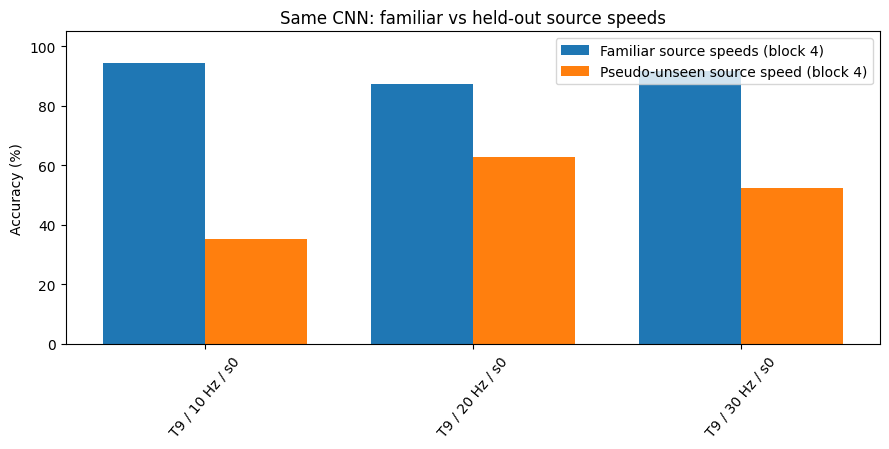

In [10]:
if source_records:
    folds_df=pd.DataFrame(source_records)
    display(folds_df[['task','held_source_hz','seed','seen_acc','held_acc',
                      'seen_macro_f1','held_macro_f1','accuracy_gap_pp']].round(3))
    summary=(folds_df.groupby('task',as_index=False)
            .agg(n_fits=('seed','size'),familiar_acc=('seen_acc','mean'),
                 pseudo_unseen_acc=('held_acc','mean'),familiar_f1=('seen_macro_f1','mean'),
                 pseudo_unseen_f1=('held_macro_f1','mean'),accuracy_gap_pp=('accuracy_gap_pp','mean')))
    display(summary.round(3))
    summary.to_csv(RESULTS_DIR/'source_crossspeed_summary.csv',index=False)
    x=np.arange(len(folds_df)); width=.38
    fig,ax=plt.subplots(figsize=(max(9,len(x)*.7),4.6))
    ax.bar(x-width/2,100*folds_df['seen_acc'].values,width,label='Familiar source speeds (block 4)')
    ax.bar(x+width/2,100*folds_df['held_acc'].values,width,label='Pseudo-unseen source speed (block 4)')
    ax.set(xticks=x,xticklabels=[f'T{r.task} / {r.held_source_hz} Hz / s{r.seed}' for r in folds_df.itertuples()],
           ylabel='Accuracy (%)',ylim=(0,105),title='Same CNN: familiar vs held-out source speeds')
    ax.tick_params(axis='x',rotation=50)
    ax.legend(loc='upper right');plt.tight_layout()
    fig.savefig(FIGURES_DIR/'source_crossspeed_accuracy_gap.png',dpi=170)
    plt.show()
else:
    print('No source-fold results yet. Run Section 9 first.')

## 11. Inspect learning curves and a six-class confusion matrix

A strong *training* score but weak held-speed score suggests domain shift / overfitting. If both familiar and held-speed scores are poor, the setup may instead be undertrained or the task difficult even within the source distribution. We show an example fold to avoid flooding the notebook with dozens of plots.

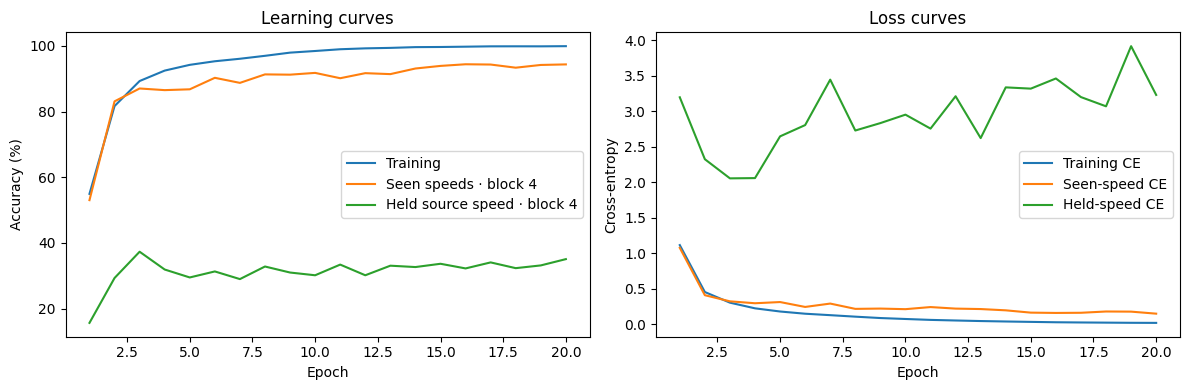

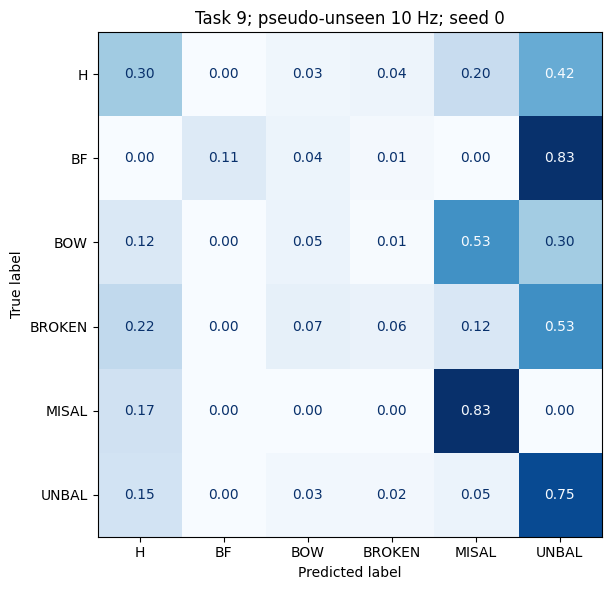

Held-speed accuracy: 35.08 %
Held-speed macro-F1: 0.2815


In [11]:
if source_runs:
    chosen=source_runs[0]
    hist=chosen['history']
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    axs[0].plot(hist['epoch'],100*hist['train_acc'],label='Training')
    axs[0].plot(hist['epoch'],100*hist['seen_val_acc'],label='Seen speeds · block 4')
    axs[0].plot(hist['epoch'],100*hist['held_val_acc'],label='Held source speed · block 4')
    axs[0].set(xlabel='Epoch',ylabel='Accuracy (%)',title='Learning curves')
    axs[0].legend()
    axs[1].plot(hist['epoch'],hist['train_loss'],label='Training CE')
    axs[1].plot(hist['epoch'],hist['seen_val_loss'],label='Seen-speed CE')
    axs[1].plot(hist['epoch'],hist['held_val_loss'],label='Held-speed CE')
    axs[1].set(xlabel='Epoch',ylabel='Cross-entropy',title='Loss curves');axs[1].legend()
    plt.tight_layout();fig.savefig(FIGURES_DIR/'source_fold_learning_curves.png',dpi=160);plt.show()

    f=chosen['fold']; m=chosen['model']
    val_loader=make_loader(D['ac'][f['held_val_idx']],D['y'][f['held_val_idx']],SOURCE_BATCH_SIZE)
    prediction=score_model(m,val_loader,collect=True)
    cm=confusion_matrix(prediction['true'],prediction['pred'],labels=np.arange(6),normalize='true')
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(cm,display_labels=CLASS_CODES).plot(ax=ax,cmap='Blues',
        values_format='.2f',colorbar=False)
    ax.set_title(f'Task {chosen["task"]}; pseudo-unseen {DOMAIN_TO_HZ[f["held_domain"]]} Hz; seed {chosen["seed"]}')
    plt.tight_layout();fig.savefig(FIGURES_DIR/'source_held_speed_confusion.png',dpi=160);plt.show()
    print('Held-speed accuracy:',round(prediction['accuracy']*100,2),'%')
    print('Held-speed macro-F1:',round(prediction['macro_f1'],4))
else:
    print('Source-fold confusion matrix available after Section 9.')

---
# Optional Experiment B — window length and overlap from the original raw recordings

**This section is optional and disabled by default.** Genti's `hustmotor_1024_v1.3.npz` contains only 1,024-point windows; it is impossible to regenerate *continuous* 4,096/8,192-point windows from it reliably.

Get the **24 original `.txt` files**, with filenames such as `H_5HZ.txt`, `BF_10HZ.txt`, from https://github.com/CHAOZHAO-1/HUSTmotor-multi-modal-dataset, and extract them to the `RAW_ROOT` Google Drive directory configured in Section 1.

We reproduce the key preprocessing logic: 5 separate 32,768-row blocks per recording, acoustic column 5 (`raw[:,4]`), z-score **within each window**, same `split=(block==4)` rule. We choose **16 windows per acquisition block for every length** to keep example counts equal (the original pipeline uses **200** windows/block). **Caveat:** overlap and total temporal coverage necessarily change with window length. This is a useful *exploratory length comparison*, not a causal isolation of temporal context alone.

We train a **second length-agnostic CNN** with the same four convolutional blocks but an **adaptive pooling head** so the number of trainable parameters is the same for all window lengths. Its scores are **not directly comparable** to the historical 1,024-point flattened-CNN benchmark.

## 12. Locate raw recordings and construct long-window NPZs

In [12]:
def locate_original_raw_files(root):
    root=Path(root)
    if not root.exists():
        raise FileNotFoundError(f'RAW_ROOT not found: {root}. Unzip all 24 raw .txt files first.')
    candidates=[root]+[p for p in root.rglob('*') if p.is_dir()]
    expected=[f'{c}_{hz}HZ.txt' for c in CLASS_CODES for hz in (5,10,20,30)]
    for folder in candidates:
        if all((folder/name).is_file() for name in expected):
            return {name:folder/name for name in expected}
    raise FileNotFoundError('Could not find the same folder containing all 24 raw HUSTmotor .txt files. '
                            'Example filename: H_5HZ.txt. Check the extracted folder hierarchy.')

def read_original_acoustic(path):
    # The time column restarts at each acquisition block; never create windows across blocks.
    with open(path,'r',errors='ignore') as f:
        header=[next(f) for _ in range(40)]
    starts=[i for i,line in enumerate(header) if line.startswith('Time (seconds)')]
    if not starts:raise ValueError(f'Unexpected raw file header: {path}')
    raw=np.loadtxt(path,skiprows=starts[0]+1,dtype=np.float64)
    if raw.shape != (163840,5):raise ValueError(f'{path.name}: expected (163840,5); got {raw.shape}')
    if not np.isfinite(raw).all():raise ValueError(f'{path.name}: NaN/Inf present')
    return raw[:,4].astype(np.float32)

def evenly_spaced_block_windows(signal,win,n_per_block):
    if win>RAW_BLOCK_SAMPLES:raise ValueError('Window longer than a 32,768-row acquisition block.')
    starts=np.rint(np.linspace(0,RAW_BLOCK_SAMPLES-win,n_per_block)).astype(np.int64)
    assert len(np.unique(starts))==n_per_block
    windows=[]; starts_absolute=[]; blocks=[]
    for block in range(N_BLOCKS):
        x=signal[block*RAW_BLOCK_SAMPLES:(block+1)*RAW_BLOCK_SAMPLES]
        windows.append(np.stack([x[s:s+win] for s in starts]))
        starts_absolute.append(starts+block*RAW_BLOCK_SAMPLES)
        blocks.append(np.full(n_per_block,block,dtype=np.int8))
    return np.concatenate(windows),np.concatenate(starts_absolute),np.concatenate(blocks)

def raw_file_manifest(raw_files):
    return [{'file':k,'size':int(path.stat().st_size),'mtime_ns':int(path.stat().st_mtime_ns)}
            for k,path in sorted(raw_files.items())]

def make_raw_npz(raw_files,win,n_per_block):
    manifest=raw_file_manifest(raw_files)
    config={'length':int(win),'n_per_block':int(n_per_block),'normalization':'per_window_zscore',
            'files':manifest,'block_split':'block4_held'}
    signature=json_id(config)
    output=RAW_CACHE_DIR/f'ac_raw_win{win}_n{n_per_block}_{signature}.npz'
    if output.is_file():
        print('Reusing verified filename/config cached dataset:',output.name)
        return output
    arrays={k:[] for k in ['ac','y','domain','block','split','start','rms_a']}
    for cls_idx,c in enumerate(CLASS_CODES):
        for dom_idx,hz in enumerate((5,10,20,30)):
            name=f'{c}_{hz}HZ.txt'
            sig=read_original_acoustic(raw_files[name])
            x,starts,blocks=evenly_spaced_block_windows(sig,win,n_per_block)
            x=x.astype(np.float64)
            centered=x-x.mean(axis=1,keepdims=True)
            rms=np.sqrt(np.mean(centered**2,axis=1))
            z=(centered/np.maximum(rms[:,None],1e-8)).astype(np.float32)
            arrays['ac'].append(z)
            arrays['rms_a'].append(rms.astype(np.float32))
            arrays['y'].append(np.full(len(z),cls_idx,dtype=np.int8))
            arrays['domain'].append(np.full(len(z),dom_idx,dtype=np.int8))
            arrays['block'].append(blocks)
            arrays['split'].append((blocks==4).astype(np.int8))
            arrays['start'].append(starts.astype(np.int32))
    merged={k:np.concatenate(v) for k,v in arrays.items()}
    merged['win_length']=np.array(win,dtype=np.int32)
    merged['per_block']=np.array(n_per_block,dtype=np.int32)
    np.savez_compressed(output,**merged)
    (output.with_suffix('.json')).write_text(json.dumps(config,indent=2))
    print('Created:',output,'| samples:',len(merged['y']))
    return output

raw_datasets={}
raw_dataset_fingerprints={}
if RUN_RAW_WINDOW_STUDY:
    raw_files=locate_original_raw_files(RAW_ROOT)  # Explicitly fail if raw files missing.
    print('Found 24 original .txt recordings.')
    for win in RAW_WINDOW_LENGTHS:
        cache=make_raw_npz(raw_files,int(win),int(RAW_WINDOWS_PER_BLOCK))
        raw_dataset_fingerprints[int(win)] = cache.stem.split('_')[-1]
        with np.load(cache,allow_pickle=False) as zz:
            raw_datasets[int(win)]={k:np.asarray(zz[k]) for k in ['ac','y','domain','block','split','start','rms_a']}
        assert raw_datasets[int(win)]['ac'].shape[-1]==int(win)
else:
    print('Long-window data generation disabled. Set RUN_RAW_WINDOW_STUDY=True and configure RAW_ROOT to enable.')

Long-window data generation disabled. Set RUN_RAW_WINDOW_STUDY=True and configure RAW_ROOT to enable.


## 13. Length-dependent overlap audit and same-capacity CNN

We document the true overlap at each length. We use **AdaptiveAvgPool1d(8)** to hold the feature vector length fixed across window sizes, preventing a longer input from automatically creating a much larger final linear layer. This is a *new controlled architecture*, not our previous baseline.

In [13]:
class LengthAgnosticCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv1d(1,16,64),nn.BatchNorm1d(16),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(16,32,16),nn.BatchNorm1d(32),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(32,64,5),nn.BatchNorm1d(64),nn.ReLU(),nn.MaxPool1d(2),
            nn.Conv1d(64,64,5),nn.BatchNorm1d(64),nn.ReLU(),nn.MaxPool1d(2),
            nn.AdaptiveAvgPool1d(8))
        self.classifier=nn.Linear(64*8,6)
    def forward(self,x):return self.classifier(self.features(x).flatten(1))

model_params=sum(p.numel() for p in LengthAgnosticCNN().parameters() if p.requires_grad)
print('Same trainable parameters for ALL lengths:',model_params)
for win in RAW_WINDOW_LENGTHS:
    with torch.no_grad():
        a=LengthAgnosticCNN().eval()(torch.zeros(2,1,int(win)))
    assert a.shape==(2,6)

if raw_datasets:
    quality=[]
    for win,dat in raw_datasets.items():
        idx=np.flatnonzero((dat['y']==0)&(dat['domain']==0)&(dat['block']==0))
        starts=np.sort(dat['start'][idx]); diffs=np.diff(starts)
        overlaps=np.maximum(0,win-diffs)/win
        quality.append({'window_length':win,'window_duration_ms':1000*win/FS,
                        'windows_per_block':len(starts),'median_stride':float(np.median(diffs)),
                        'adjacent_overlap_pct':100*float(np.mean(overlaps)),
                        'fraction_of_block_covered_approx':min(1.,len(starts)*win/RAW_BLOCK_SAMPLES)})
    quality_df=pd.DataFrame(quality)
    display(quality_df.round(3))
    quality_df.to_csv(RESULTS_DIR/'length_study_overlap_diagnostics.csv',index=False)
else:
    print('No raw-derived datasets yet; run Section 12 with RUN_RAW_WINDOW_STUDY=True.')

Same trainable parameters for ALL lengths: 43542
No raw-derived datasets yet; run Section 12 with RUN_RAW_WINDOW_STUDY=True.


## 14. RUN optional: longer-window source-speed folds

For each window length, we hold out exactly the same source speeds and use the same 6-class loss, training epochs, batch size, learning rate and parameter count. **No actual unseen target speed is evaluated.**

All cache files include the dataset hash and configuration. Results are separate from Experiment A.

In [14]:
raw_records=[]
if RUN_RAW_WINDOW_STUDY:
    for win,dat in raw_datasets.items():
        for task in RAW_TASKS:
            for fold in source_folds(dat,task):
                for seed in RAW_SEEDS:
                    config={'family':'length_agnostic_cnn_adaptive8_v1','win':int(win),
                        'n_per_block':int(RAW_WINDOWS_PER_BLOCK),'task':int(task),
                        'held_domain':int(fold['held_domain']),'seen_domains':list(fold['seen_domains']),
                        'seed':int(seed),'epochs':int(RAW_EPOCHS),'lr':float(RAW_LR),
                        'batch_size':int(RAW_BATCH_SIZE),'normalization':'window_zscore',
                        'checkpoint_rule':'fixed_final_epoch',
                        'raw_cache_size':int(dat['ac'].shape[0]),
                        'raw_dataset_fingerprint':raw_dataset_fingerprints[int(win)]}
                    path=MODELS_DIR/f'raw_len{win}_task{task}_held{DOMAIN_TO_HZ[fold["held_domain"]]}_s{seed}_{json_id(config)}.pt'
                    restored=load_run(path,config,LengthAgnosticCNN)
                    if restored is not None:
                        model,hist=restored
                        print('REUSED',path.name)
                    else:
                        get=lambda k:(dat['ac'][fold[k]],dat['y'][fold[k]])
                        print(f'\nRaw-window length={win}, Task={task}, pseudo-unseen={DOMAIN_TO_HZ[fold["held_domain"]]}Hz, seed={seed}')
                        model,hist=train_fixed_epoch_cnn(get('train_idx'),get('seen_val_idx'),
                            get('held_val_idx'),LengthAgnosticCNN,seed,RAW_EPOCHS,RAW_LR,RAW_BATCH_SIZE)
                        save_run(path,model,hist,config)
                    last=hist.iloc[-1]
                    raw_records.append({'window_length':win,'duration_ms':1000*win/FS,
                        'task':task,'held_source_hz':DOMAIN_TO_HZ[fold['held_domain']],
                        'seed':seed,'seen_acc':float(last['seen_val_acc']),
                        'held_acc':float(last['held_val_acc']),
                        'seen_macro_f1':float(last['seen_val_f1']),
                        'held_macro_f1':float(last['held_val_f1']),
                        'gap_pp':100*float(last['seen_val_acc']-last['held_val_acc']),
                        'checkpoint':str(path)})
                    pd.DataFrame(raw_records).to_csv(RESULTS_DIR/'raw_window_length_fold_results.csv',index=False)
    print('Finished optional raw study fits:',len(raw_records))
else:
    print('Optional raw-window training skipped.')

Optional raw-window training skipped.


## 15. Visualize results for window lengths (if generated)

In [15]:
if raw_records:
    raw_df=pd.DataFrame(raw_records)
    raw_summary=(raw_df.groupby(['window_length','duration_ms'],as_index=False)
        .agg(familiar_acc=('seen_acc','mean'),pseudo_unseen_acc=('held_acc','mean'),
             pseudo_unseen_macro_f1=('held_macro_f1','mean'),gap_pp=('gap_pp','mean'),
             n_fits=('seed','size')))
    display(raw_summary.round(3))
    raw_summary.to_csv(RESULTS_DIR/'raw_window_length_summary.csv',index=False)
    fig,ax=plt.subplots(figsize=(8.5,4.3))
    ax.plot(raw_summary['duration_ms'],100*raw_summary['familiar_acc'],'o-',label='Familiar source speeds')
    ax.plot(raw_summary['duration_ms'],100*raw_summary['pseudo_unseen_acc'],'o-',label='Held source speeds')
    ax.set(xlabel='Window duration (ms)',ylabel='Fixed-epoch accuracy (%)',
           title='Exploratory length study (same-capacity CNN, source-only folds)')
    ax.legend();plt.tight_layout()
    fig.savefig(FIGURES_DIR/'raw_window_length_sourcecv.png',dpi=170)
    plt.show()
    print('CAUTION: Equal windows/block does not imply equal overlap or temporal coverage.')
else:
    print('No raw length study was run. This is expected for the default settings.')

No raw length study was run. This is expected for the default settings.


## 16. Save an audit manifest and interpret the evidence

A **large familiar-versus-held-speed gap** suggests domain shift is already detectable *within the source speeds*, so a changed validation strategy is urgently justified.

- If held-speed results are weak **and** familiar-speed performance is strong, first address the representation and domain shift (window duration, time/frequency patterns, possible noise/recording artifacts).
- If even familiar-speed results are weak, review preprocessing, optimizer, training duration and class-specific errors before assuming domain shift explains everything.
- If longer windows consistently improve *source-only* held-speed macro-F1, this supports taking longer contexts to the **next controlled experiment**. It does not prove the causal mechanism because overlap and coverage also change.
- If all length variants are weak, prioritize spectral features, domain-adaptive normalization and acoustic acquisition checks, rather than simply increasing model depth.

**No claims about improving the real unseen 5/10/20/30 Hz benchmark can be made from these audits alone.** The saved manifests allow us to make reproducible next steps.

In [16]:
manifest={'university':'Université de technologie de Compiègne (UTC)',
          'experiment':'Acoustic preprocessing and source-speed validation audit',
          'created_at_utc':datetime.now(timezone.utc).isoformat(),
          'dataset':'hustmotor_1024_v1.3.npz','sha256':actual_sha,
          'protocol':'Acquire-block split; actual task target speed completely excluded',
          'source_audit':{'tasks':list(AUDIT_TASKS),'seeds':list(AUDIT_SEEDS),
                          'epochs':SOURCE_EPOCHS,'lr':SOURCE_LR,'batch_size':SOURCE_BATCH_SIZE,
                          'model':'original four-block 1D CNN; 3520 flatten features',
                          'checkpoint_rule':'last epoch'},
          'raw_study':{'enabled':bool(RUN_RAW_WINDOW_STUDY),
                       'lengths':list(RAW_WINDOW_LENGTHS),
                       'windows_per_block':RAW_WINDOWS_PER_BLOCK,
                       'tasks':list(RAW_TASKS),'seeds':list(RAW_SEEDS),
                       'epochs':RAW_EPOCHS,'batch_size':RAW_BATCH_SIZE,
                       'model':'four-block CNN + adaptive pooling to 8 bins'},
          'versions':{'python':platform.python_version(),'torch':torch.__version__,
                      'numpy':np.__version__,'pandas':pd.__version__},
          'source_run_count':len(source_records),'raw_run_count':len(raw_records),
          'important_limitations':[
              'Source held-speed scores are development diagnostics, not a locked external test.',
              'The historical 48.45% original-CNN result uses 3 training source speeds, not 2.',
              'Equal-count longer windows have unequal overlap and temporal coverage.',
              'No actual target-speed samples used anywhere in this notebook.'
          ]}
manifest_path=RESULTS_DIR/'experiment_manifest.json'
manifest_path.write_text(json.dumps(manifest,indent=2,default=str))
print('Manifest:',manifest_path)
print('Results folder:',RESULTS_DIR)
print('Figures folder:',FIGURES_DIR)
print('Checkpoints folder:',MODELS_DIR)
print('\nNEXT STEP: Send me this executed notebook and the source_crossspeed_summary.csv')
print('           If you also ran the raw study, include raw_window_length_summary.csv')

Manifest: /content/drive/MyDrive/HUSTmotor_Acoustic_Pipeline_Audit_UTC/results/experiment_manifest.json
Results folder: /content/drive/MyDrive/HUSTmotor_Acoustic_Pipeline_Audit_UTC/results
Figures folder: /content/drive/MyDrive/HUSTmotor_Acoustic_Pipeline_Audit_UTC/figures
Checkpoints folder: /content/drive/MyDrive/HUSTmotor_Acoustic_Pipeline_Audit_UTC/checkpoints

NEXT STEP: Send me this executed notebook and the source_crossspeed_summary.csv
           If you also ran the raw study, include raw_window_length_summary.csv


---
### References and methodological notes

- **Genti's shared preprocessing:** [Genti24-bit/ISCF_Project/preprocess_hustmotor.py](https://github.com/Genti24-bit/ISCF_Project/blob/main/preprocess_hustmotor.py). We mirrored its *block/window splitting* and acoustic-channel selection for the optional raw study.
- **Original raw files:** [CHAOZHAO-1/HUSTmotor-multi-modal-dataset](https://github.com/CHAOZHAO-1/HUSTmotor-multi-modal-dataset). Obtain and cite according to the source project's instructions.
- **Lecture 02 — Training Neural Networks**, Sylvain Rousseau: input standardization, validation vs testing, optimization, regularization and early stopping. Those ideas motivated separating **source-domain development validation** from the **final target test**.
- **Previous original-CNN benchmark:** 48.45% unseen-speed overall accuracy (10 seeds × 4 tasks, z-score, source block model selection). The source-only experiments here do **not** reproduce that exact baseline; their purpose is to investigate why its cross-speed generalization is weak.

**Important:** If you change the preprocessing or sampling protocol, label the resulting dataset with a new version. Never report its results as directly comparable to the original 24,000-window v1.3 data without explaining the changed setup.